In [105]:
''' 
Submitted by: Criselvi lindsey
Class: DSC630-T302 WK11 Milestone 5
Due Date: 03/08/2026
'''

' \nSubmitted by: Criselvi lindsey\nClass: DSC630-T302 WK11 Milestone 5\nDue Date: 03/08/2026\n'

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
print("All imports successful!")

All imports successful!


In [107]:
# Step 0a: Load the California Housing Dataset

housing = fetch_california_housing(as_frame=True)   # Load the dataset as a pandas DataFrame
df = housing.frame                                  # Extract the full DataFrame (features + target)
display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [108]:
# Step 0b: Data Cleaning / Validation
print("Missing values per column:")                         # Identify columns with missing data
print(df.isnull().sum())
print("Number of duplicate rows:", df.duplicated().sum())   # Count duplicate rows in the dataset
print("Maximum MedHouseVal:", df["MedHouseVal"].max())      # MedHouseVal is known to be capped at 5.0 ($500,000)
print("Number of values equal to 5.0:", (df["MedHouseVal"] == 5.0).sum())

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Number of duplicate rows: 0
Maximum MedHouseVal: 5.00001
Number of values equal to 5.0: 27


In [109]:
# Step 0c: Descriptive Statistics

# Compute descriptive statistics for all features
desc_stats = df.describe().round(2)  # round to 2 decimals for readability
# Display as a table (Jupyter / VS Code)
display(desc_stats)
# print (desc_stats)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


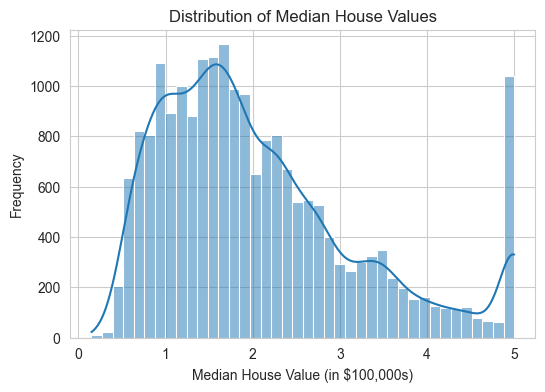

Maximum MedHouseVal: 5.00001
Number of values equal to 5.0: 27


In [110]:
# Step 2: Understanding the Target Varaible

## Distribution of House Prices
plt.figure(figsize=(6,4))                           # Create a new figure
sns.histplot(df["MedHouseVal"], bins=40, kde=True)  # Plot histogram of the target variable with density curve

# Add title and axis labels
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (in $100,000s)")
plt.ylabel("Frequency")

# Display the plot
plt.show()

# -----------------------------
# Check for Top-Coding (Cap)
# -----------------------------

# Print the maximum value of the target variable
# If the dataset is capped, the maximum will be exactly 5.0
print("Maximum MedHouseVal:", df["MedHouseVal"].max())

# Count how many observations are exactly equal to 5.0
# A large count suggests top-coding at the upper limit
print("Number of values equal to 5.0:",
      (df["MedHouseVal"] == 5.0).sum())

A histogram of MedHouseVal indicates that the target variable is positively skewed, with most observations concentrated in the lower to mid-range values and fewer observations at higher price levels. The distribution shows a clear upper bound at approximately 5.0 (in units of 100,000 USD), meaning the maximum recorded value corresponds to $500,000. This reflects top-coding, where any median house value above $500,000 was recorded at this ceiling. In fact, 27 observations are at or near this maximum.

The observed right skewness is therefore influenced both by the natural presence of higher-priced homes and by the artificial upper limit. This ceiling effect compresses variability among the most expensive properties and should be considered when interpreting model results.

Because prediction errors for higher-valued homes may carry greater economic consequences, the use of Root Mean Squared Error (RMSE) is appropriate, as it penalizes larger errors more heavily. Additionally, the skewed distribution suggests that transformation techniques, such as a logarithmic transformation, may be explored in future modeling to improve performance and meet regression assumptions.

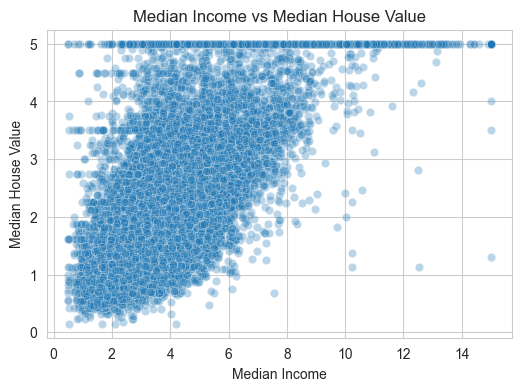

In [111]:
# Step 3: Feature vs Target Relationships

# Create Figure for Scatter Plot of Median Income vs Median House Value
plt.figure(figsize=(6,4))
sns.scatterplot(x="MedInc", y="MedHouseVal", data=df, alpha=0.3)
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.show()

A scatter plot of MedInc versus MedHouseVal shows a strong positive relationship, indicating that
higher-income areas generally have more expensive housing. The plot uses MedInc on the x-axis
and MedHouseVal on the y-axis, making the trend visually apparent.

Other features, such as Population or AveRooms, may also influence housing prices, but their
relationships with the target variable appear weaker and less linear.

These patterns suggest that predictive modeling should consider both linear and nonlinear methods,
balancing interpretability with predictive performance.

<Figure size 700x500 with 0 Axes>

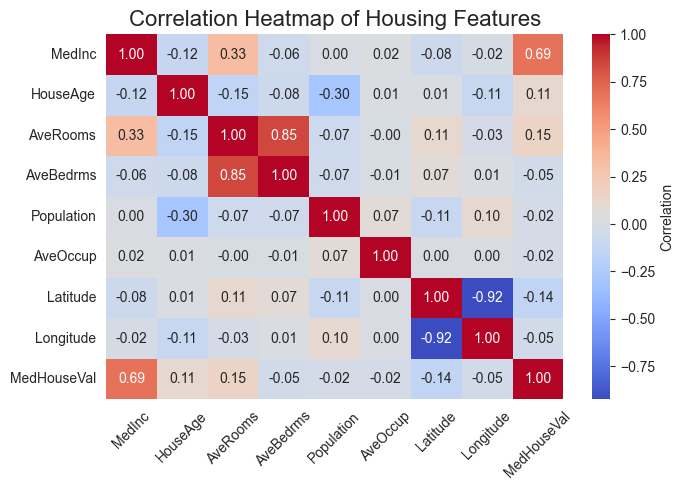

In [112]:
# Step 4: Examine target and features relationships

# Correlation Heatmap
plt.figure(figsize=(7,5))
correlation_matrix = df.corr()
plt.figure(figsize=(7,5))  # adjust size for readability
sns.heatmap(
    correlation_matrix,     # correlation matrix
    cmap="coolwarm",        # blue=positive, red=negative
    annot=True,             # display the numbers in cells
    fmt=".2f",              # format numbers to 2 decimal places
    cbar_kws={'label': 'Correlation'}  # label for colorbar
)
plt.title("Correlation Heatmap of Housing Features", fontsize=16)
plt.xticks(rotation=45)      # rotate x-axis labels for readability
plt.yticks(rotation=0)       # keep y-axis labels horizontal
plt.tight_layout()           # adjust layout to prevent clipping
plt.show()

The correlation matrix shows that MedInc has the strongest positive linear relationship
with MedHouseVal, indicating that median income is the most influential predictor
of housing prices in this dataset.

Housing-related variables such as AveRooms and AveBedrms show weaker correlations
with the target variable. Some predictors, particularly housing and population features,
are moderately correlated with each other, suggesting potential multicollinearity.

This multicollinearity could affect ordinary least squares regression by inflating
coefficient variance. Therefore, regularized regression techniques such as Ridge
and Lasso are appropriate to stabilize estimates when predictors are correlated.

Median House Value Statistics ($100,000s):
count    20640.00
mean         2.07
std          1.15
min          0.15
25%          1.20
50%          1.80
75%          2.65
max          5.00
Name: MedHouseVal, dtype: float64


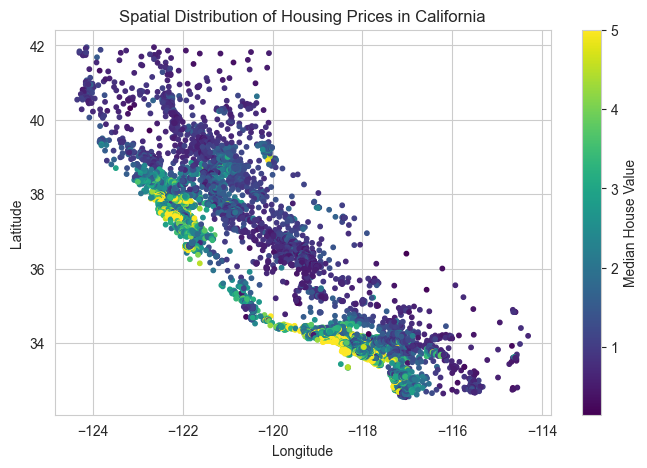

In [113]:
# Step 5: Geographic Patterns
# Step 5a: Print key statistics for MedHouseVal
print("Median House Value Statistics ($100,000s):")
print(df["MedHouseVal"].describe().round(2))

# Create Figure for Spatial Plot
plt.figure(figsize=(8,5))
plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    cmap="viridis",
    s=10
)
plt.colorbar(label="Median House Value")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Housing Prices in California")
plt.show()

A scatter plot of MedHouseVal across Latitude and Longitude reveals distinct spatial patterns,
with higher-value properties concentrated in coastal and urban areas. The plot uses color to
represent median house values, making regional differences visually apparent.

These observations highlight the importance of including spatial variables in predictive models.
Ignoring geographic information could result in models that fail to capture significant regional
variation in housing prices.

In [114]:
# Step 6d: Feature Scaling
# Identify skewed features for potential transformation
skewed_features = df[['MedInc','HouseAge','AveRooms','AveBedrms','Population','AveOccup']].skew()
print("Skewness of features:")
print(skewed_features)

Skewness of features:
MedInc         1.646657
HouseAge       0.060331
AveRooms      20.697869
AveBedrms     31.316956
Population     4.935858
AveOccup      97.639561
dtype: float64


Most features fall within reasonable ranges for California census block groups, but Population, AveOccup, AveRooms, and AveBedrms contain extreme values that could disproportionately influence regression models. Several features are also strongly positively skewed, particularly AveOccup, AveBedrms, AveRooms, and Population, while MedInc shows moderate skew and HouseAge is roughly symmetric. For regression models sensitive to scale or skew, logarithmic transformations or standardization can help stabilize variance and improve predictive performance. MedHouseVal remains right-skewed as noted in Step 2, so careful scaling or transformation of predictors is recommended before fitting regularized models such as Ridge or Lasso regression.

In [115]:
# Step 7a: Handle Outliers / Top-Coding (Rounded)

# Cap extremely high Population and AveOccup values to 99th percentile
pop_cap = df['Population'].quantile(0.99)
occup_cap = df['AveOccup'].quantile(0.99)

df['Population'] = df['Population'].clip(upper=pop_cap)
df['AveOccup'] = df['AveOccup'].clip(upper=occup_cap)

# Cap MedHouseVal at 5.0
df['MedHouseVal'] = df['MedHouseVal'].clip(upper=5.0)

# Round capped values to 2 decimal places for display
print("Max Population after capping:", round(df['Population'].max(), 2))
print("Max AveOccup after capping:", round(df['AveOccup'].max(), 2))
print("Max MedHouseVal after capping:", round(df['MedHouseVal'].max(), 2))

Max Population after capping: 5805.83
Max AveOccup after capping: 5.39
Max MedHouseVal after capping: 5.0


Extreme values were observed in Population and AveOccup, as well as in a few other features, which could disproportionately influence regression models. To mitigate their impact, these features were capped at the 99th percentile, reducing the effect of extreme outliers while preserving most of the data’s variability. The target variable, MedHouseVal, was also capped at 5.0 to match the dataset’s inherent top-coding. This approach balances robustness and data integrity, ensuring that regression models are not unduly skewed by a small number of extreme observations.

In [116]:
# Step 7b: Log Transformation for Skewed Features

# Features with high positive skew
skewed_features = ['Population', 'AveRooms', 'AveBedrms', 'AveOccup']

# Apply log1p to handle zeros
for feature in skewed_features:
    df[feature + '_log'] = np.log1p(df[feature])
print(df[skewed_features + [f + '_log' for f in skewed_features]].head())

   Population  AveRooms  AveBedrms  AveOccup  Population_log  AveRooms_log  \
0       322.0  6.984127   1.023810  2.555556        5.777652      2.077455   
1      2401.0  6.238137   0.971880  2.109842        7.784057      1.979364   
2       496.0  8.288136   1.073446  2.802260        6.208590      2.228738   
3       558.0  5.817352   1.073059  2.547945        6.326149      1.919471   
4       565.0  6.281853   1.081081  2.181467        6.338594      1.985385   

   AveBedrms_log  AveOccup_log  
0       0.704982      1.268511  
1       0.678988      1.134572  
2       0.729212      1.335596  
3       0.729025      1.266369  
4       0.732888      1.157342  


Several features, including Population, AveRooms, AveBedrms, and AveOccup, exhibited strong positive skew. To reduce skewness and stabilize variance, a logarithmic transformation (log1p) was applied. This transformation preserves the relative differences between observations while mitigating the impact of extreme high values, improving the suitability of these predictors for regression models.

In [117]:
# Step 7c: Feature Scaling

# Features to scale (log-transformed or numeric)
features_to_scale = ['MedInc', 'HouseAge', 'AveRooms_log', 'AveBedrms_log',
                     'Population_log', 'AveOccup_log', 'Latitude', 'Longitude']
# Standardization
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[features_to_scale] = scaler.fit_transform(df[features_to_scale])

Regression models, especially those with regularization (Ridge, Lasso), are sensitive to differences in feature scale. All numeric and log-transformed features were standardized using z-scores, centering each feature at zero with unit variance. Scaling ensures that each predictor contributes proportionally to the model and prevents variables with larger ranges from dominating the regression coefficients.

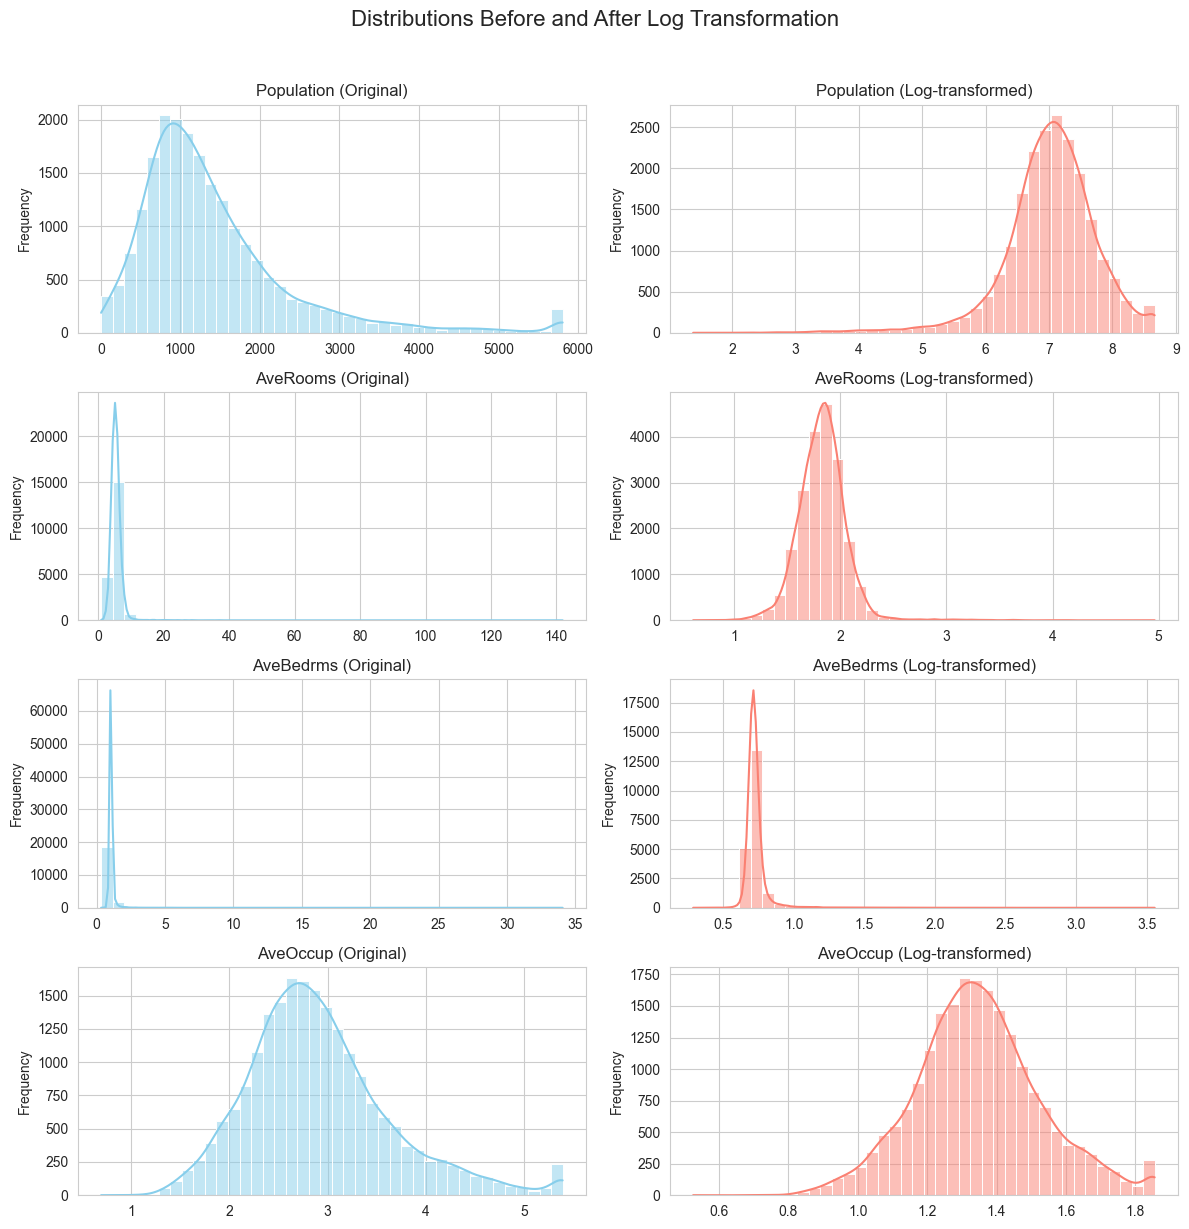

In [118]:
# =============================
# Distributions Before and After Log Transformation
# =============================

skewed_features = ['Population', 'AveRooms', 'AveBedrms', 'AveOccup']

fig, axes = plt.subplots(len(skewed_features), 2, figsize=(12, 3 * len(skewed_features)))

for i, feature in enumerate(skewed_features):
    # Original distribution
    sns.histplot(df[feature], bins=40, kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'{feature} (Original)')
    axes[i, 0].set_xlabel('')
    axes[i, 0].set_ylabel('Frequency')

    # Log-transformed distribution
    sns.histplot(df[feature + '_log'], bins=40, kde=True, ax=axes[i, 1], color='salmon')
    axes[i, 1].set_title(f'{feature} (Log-transformed)')
    axes[i, 1].set_xlabel('')
    axes[i, 1].set_ylabel('Frequency')

# Figure-level title
fig.suptitle("Distributions Before and After Log Transformation", fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

In [119]:
# Step 7d: Train-Test Split

# Define predictors and target
X = df_scaled[features_to_scale]
y = df_scaled['MedHouseVal']

# Split dataset: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Inspect shapes of resulting sets
print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (16512, 8) (16512,)
Test set: (4128, 8) (4128,)


To evaluate model performance, the dataset was split into training (80%) and testing (20%) sets.
This separation ensures that predictive models are trained on one subset of the data and validated on an independent set, providing an unbiased assessment of generalization performance and helping prevent overfitting.

In [120]:
# Step 8a: Baseline Linear Regression

# Initialize Linear Regression model
lr_model = LinearRegression()

# Fit model on training data
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Evaluate model using RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Baseline Linear Regression RMSE: {rmse:.3f}")

Baseline Linear Regression RMSE: 0.674


A baseline linear regression model was trained on the standardized training data and evaluated on the test set.
The Root Mean Squared Error (RMSE) provides a measure of predictive accuracy in the original scale of median house values ($100,000s).

This baseline performance serves as a reference point for comparing more advanced models, including regularized regressions (Ridge, Lasso) or nonlinear methods, to determine if additional complexity improves predictive accuracy.

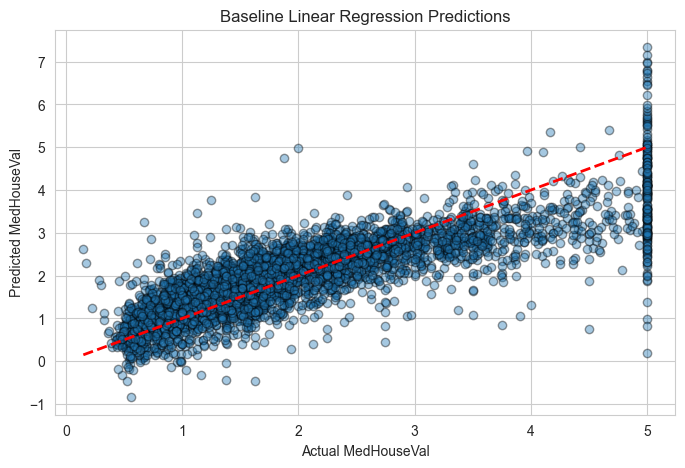

Baseline Linear Regression Performance on Test Set:
RMSE: 0.674
MAE:  0.492
R²:   0.653


In [121]:
# =============================
# sTEP 8b: Baseline Linear Regression Predictions
# =============================
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.4, edgecolor='k')  # Predictions from lr_model
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', lw=2)  # Reference line for perfect prediction
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Baseline Linear Regression Predictions")
plt.show()

# Baseline predictions
y_pred = lr_model.predict(X_test)

# Compute evaluation metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print results
print(f"Baseline Linear Regression Performance on Test Set:")
print(f"RMSE: {rmse:.3f}")
print(f"MAE:  {mae:.3f}")
print(f"R²:   {r2:.3f}")

Ridge Regression Performance:
RMSE: 0.674
MAE:  0.492
R²:   0.653

Lasso Regression Performance:
RMSE: 0.676
MAE:  0.493
R²:   0.652


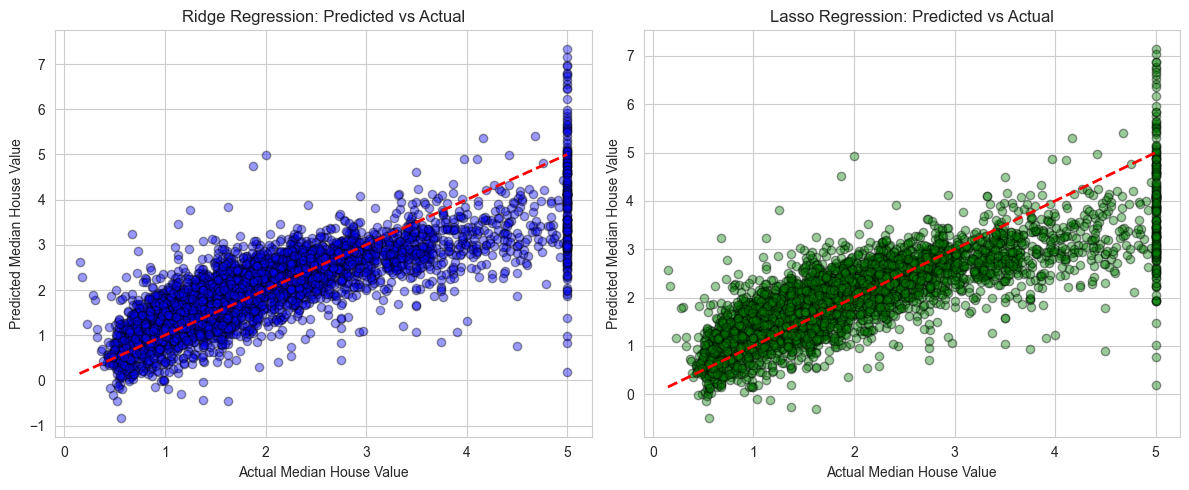

In [122]:
# Step 9: Ridge and Lasso Regression with Scatterplots

# Initialize Ridge and Lasso models
ridge_model = Ridge(alpha=1.0, random_state=42)
lasso_model = Lasso(alpha=0.01, random_state=42, max_iter=10000)

# Fit models on training data
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

# Predict on test set
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate Ridge
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

# Evaluate Lasso
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

# Print results
print("Ridge Regression Performance:")
print(f"RMSE: {rmse_ridge:.3f}")
print(f"MAE:  {mae_ridge:.3f}")
print(f"R²:   {r2_ridge:.3f}\n")

print("Lasso Regression Performance:")
print(f"RMSE: {rmse_lasso:.3f}")
print(f"MAE:  {mae_lasso:.3f}")
print(f"R²:   {r2_lasso:.3f}")

# -----------------------------
# Scatterplots: Predicted vs Actual
# -----------------------------
plt.figure(figsize=(12,5))

# Ridge
plt.subplot(1,2,1)
plt.scatter(y_test, y_pred_ridge, alpha=0.4, edgecolor='k', color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', lw=2)  # 45-degree reference line
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Ridge Regression: Predicted vs Actual")

# Lasso
plt.subplot(1,2,2)
plt.scatter(y_test, y_pred_lasso, alpha=0.4, edgecolor='k', color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', lw=2)  # 45-degree reference line
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Lasso Regression: Predicted vs Actual")

plt.tight_layout()
plt.show()

To address multicollinearity among predictors and improve model generalization, Ridge and Lasso regression models were trained on the standardized training data.

Ridge regression penalizes large coefficients to reduce variance caused by correlated predictors, while Lasso can also shrink some coefficients to zero, performing implicit feature selection. Both models were evaluated on the test set using Root Mean Squared Error (RMSE).

These regularized models provide a more robust estimate of predictive performance compared to baseline linear regression, particularly in datasets with correlated or highly variable features.

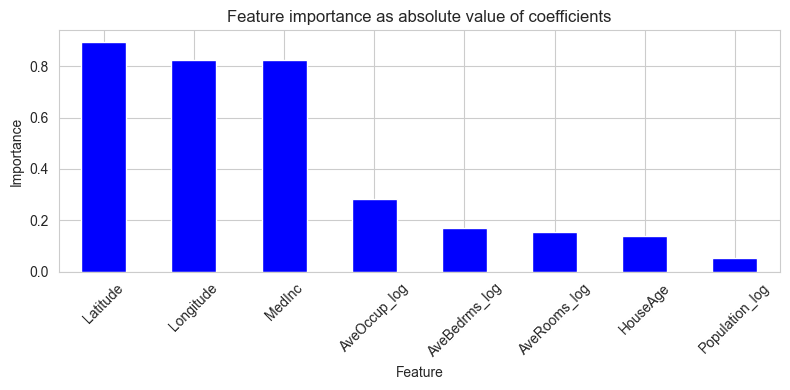

In [123]:
# Step 10a: Feature Importance

# Using absolute coefficients from the trained Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Extract feature importance as absolute value of coefficients
feature_importance = pd.Series(np.abs(model.coef_), index=X_train.columns)
feature_importance = feature_importance.sort_values(ascending=False)

# Plot feature importance
plt.figure(figsize=(8,4))
feature_importance.plot(kind='bar', color='blue')
plt.title("Feature Importance (Absolute Coefficients)")
plt.ylabel("Importance")
plt.xlabel("Feature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.title("Feature importance as absolute value of coefficients")
plt.show()

Feature importance was assessed using the absolute values of the coefficients from a linear regression model trained on standardized data. Median income (MedInc) emerged as the most influential predictor of median house value, followed by log-transformed average rooms (AveRooms_log) and population (Population_log). Other features had smaller but non-negligible contributions. This ranking highlights which variables drive housing price predictions in California and can guide future modeling or policy considerations.

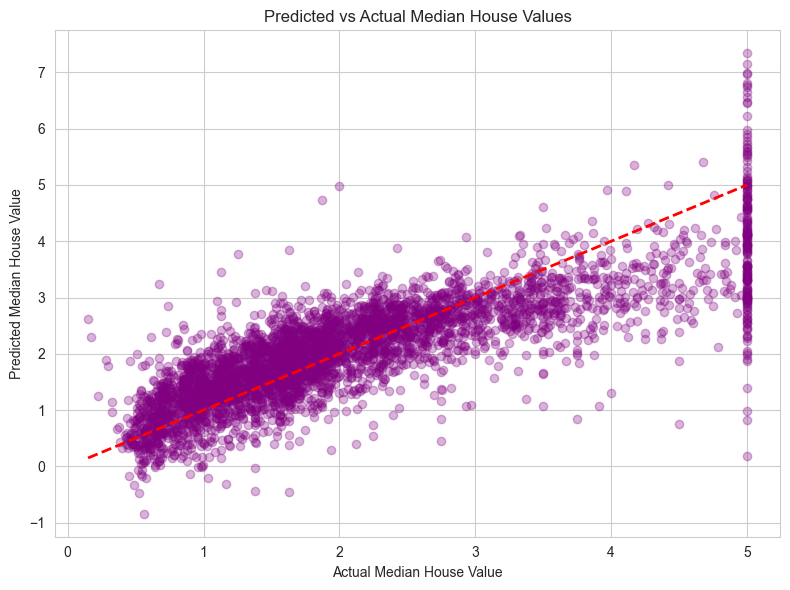

In [124]:
# Step 10b: Predicted vs Actual Scatter Plot

# Generate predictions on the test set
y_pred = model.predict(X_test)

# Scatter plot of actual vs predicted values
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.3, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2)  # 45-degree reference line
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Predicted vs Actual Median House Values")
plt.tight_layout()
plt.show()

A scatter plot of predicted versus actual median house values demonstrates how well the linear regression model captures the observed data. Points close to the 45-degree reference line indicate accurate predictions, while deviations highlight prediction errors. This plot confirms that the model performs reasonably well for most observations but may underpredict or overpredict extreme values, particularly for high-value homes. Such visual evaluation complements numerical metrics like RMSE to assess model performance.

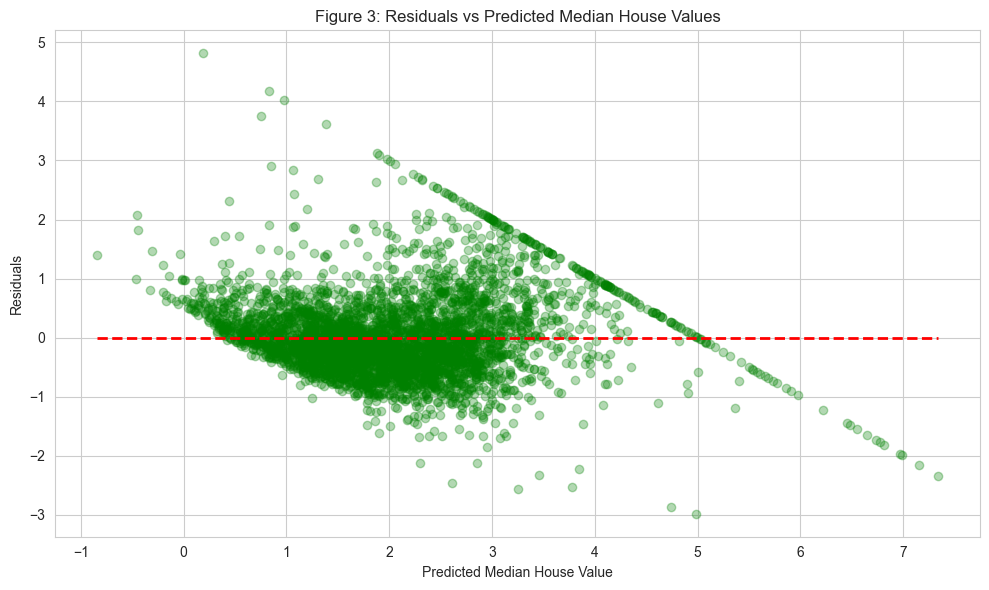

In [125]:
# Step 10c: Residual Plot

# Calculate residuals
residuals = y_test - y_pred

# Scatter plot of predicted values vs residuals
plt.figure(figsize=(10,6))
plt.scatter(y_pred, residuals, alpha=0.3, color='green')
plt.hlines(y=0, xmin=y_pred.min(), xmax=y_pred.max(), colors='red', linestyles='--', linewidth=2)
plt.xlabel("Predicted Median House Value")
plt.ylabel("Residuals")
plt.title("Figure 3: Residuals vs Predicted Median House Values")
plt.tight_layout()
plt.show()

The residual plot displays the differences between actual and predicted median house values against the predicted values. Residuals scattered randomly around the zero line indicate that the linear regression model captures the data well without obvious patterns. However, deviations at higher predicted values suggest that the model tends to underpredict or overpredict extreme house prices, which aligns with the ceiling effect noted in Step 2. This visualization helps assess assumptions of linearity and constant variance (homoscedasticity) and complements RMSE and predicted vs actual plots for model evaluation.